In [1]:
import pandas as pd
import matplotlib.pyplot as mtp
import numpy as np


In [2]:
df=pd.read_csv("iris.csv")
df


,Sepal_length,Sepal_Width,Species
0,5.3,3.7,Setosa
1,5.1,3.8,Setosa
2,7.2,3.0,Virginica
3,5.4,3.4,Setosa
4,5.1,3.3,Setosa
5,7.4,2.8,Setosa
6,6.1,2.8,Virginica
7,7.3,2.9,Setosa
8,6.0,2.7,Setosa
9,5.8,2.8,Setosa


In [3]:
# to view dim of dataset
df.shape 

(14, 3)

In [4]:
df.head()

,Sepal_length,Sepal_Width,Species
0,5.3,3.7,Setosa
1,5.1,3.8,Setosa
2,7.2,3.0,Virginica
3,5.4,3.4,Setosa
4,5.1,3.3,Setosa


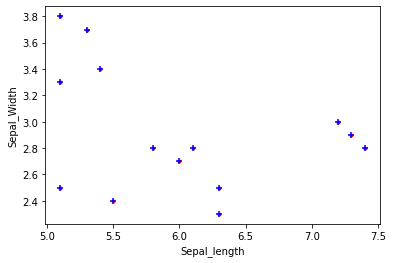

In [20]:
import matplotlib.pyplot as plt
plt.xlabel('Sepal_length')
plt.ylabel('Sepal_Width')
plt.scatter(df['Sepal_length'], df['Sepal_Width'],color="red",marker='.')
plt.scatter(df['Sepal_length'], df['Sepal_Width'],color="blue",marker='+')

In [8]:
x= df.iloc[:, [0,1]].values
y = df.iloc[:,2].values

In [9]:
x

array([[5.3, 3.7],
       [5.1, 3.8],
       [7.2, 3. ],
       [5.4, 3.4],
       [5.1, 3.3],
       [7.4, 2.8],
       [6.1, 2.8],
       [7.3, 2.9],
       [6. , 2.7],
       [5.8, 2.8],
       [6.3, 2.3],
       [5.1, 2.5],
       [6.3, 2.5],
       [5.5, 2.4]])

In [10]:
y

array(['Setosa', 'Setosa', 'Virginica', 'Setosa', 'Setosa', 'Setosa',
       'Virginica', 'Setosa', 'Setosa', 'Setosa', 'Virginica',
       'Virginica', 'Virginica', 'Setosa'], dtype=object)

In [11]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.20, random_state = 0)

In [12]:
x_train

array([[5.1, 2.5],
       [7.2, 3. ],
       [5.5, 2.4],
       [5.8, 2.8],
       [5.1, 3.8],
       [7.3, 2.9],
       [6.3, 2.3],
       [5.4, 3.4],
       [5.3, 3.7],
       [7.4, 2.8],
       [6.3, 2.5]])

In [13]:
y_train

array(['Virginica', 'Virginica', 'Setosa', 'Setosa', 'Setosa', 'Setosa',
       'Virginica', 'Setosa', 'Setosa', 'Setosa', 'Virginica'],
      dtype=object)

In [14]:
from sklearn.neighbors import KNeighborsClassifier
classifier = KNeighborsClassifier(n_neighbors = 5, metric ='minkowski',p = 2)
classifier.fit(x_train, y_train)


KNeighborsClassifier()

In [15]:
y_pred = classifier.predict(x_test)
y_pred

array(['Setosa', 'Setosa', 'Setosa'], dtype=object)

In [16]:
from sklearn.metrics import confusion_matrix,accuracy_score
cm = confusion_matrix(y_test, y_pred)
ac = accuracy_score(y_test,y_pred)
cm

array([[2, 0],
       [1, 0]])

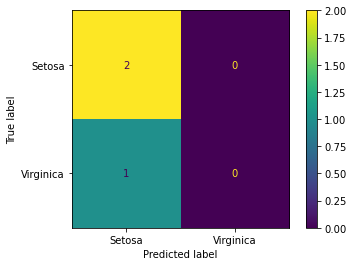

In [17]:
from sklearn.metrics import plot_confusion_matrix
plot_confusion_matrix(classifier , x_test, y_test)  

In [30]:
#Hper parametric tunning
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
import numpy as np
 
#Creating the hyperparameter grid
param_grid = {'n_neighbors':[5,6,7,8,9,10,11],'p':[1,2]}
 
# Instantiating logistic regression classifier
classifier = KNeighborsClassifier()

# Instantiating the GridSearchCV object
classifier_cv = GridSearchCV(classifier, param_grid, cv = 5)
classifier_cv.fit(x, y)

GridSearchCV(cv=5, estimator=KNeighborsClassifier(),
             param_grid={'n_neighbors': [5, 6, 7, 8, 9, 10, 11], 'p': [1, 2]})

In [31]:
classifier_cv.best_params_

{'n_neighbors': 7, 'p': 2}

In [32]:
from sklearn.neighbors import KNeighborsClassifier
classifier = KNeighborsClassifier(n_neighbors = 7,p = 2)
classifier.fit(x_train, y_train)


KNeighborsClassifier(n_neighbors=7)

In [33]:
y_pred = classifier.predict(x_test)
y_pred

array(['Setosa', 'Virginica', 'Setosa'], dtype=object)

In [34]:
from sklearn.metrics import confusion_matrix,accuracy_score
cm = confusion_matrix(y_test, y_pred)
ac = accuracy_score(y_test,y_pred)
cm

array([[2, 0],
       [0, 1]])

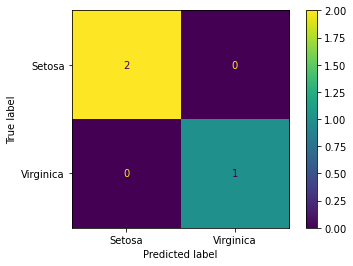

In [35]:
from sklearn.metrics import plot_confusion_matrix
plot_confusion_matrix(classifier , x_test, y_test)  

In [19]:
from sklearn.metrics import classification_report
classifier.fit(x_train,y_train)
prediction = classifier.predict(x_test)
target_names = ['0','1']
print(classification_report(y_test, prediction.reshape(-1,1), target_names=target_names))


              precision    recall  f1-score   support

           0       0.67      1.00      0.80         2
           1       0.00      0.00      0.00         1

    accuracy                           0.67         3
   macro avg       0.33      0.50      0.40         3
weighted avg       0.44      0.67      0.53         3



/home/ubuntu/anaconda3/lib/python3.8/site-packages/sklearn/metrics/_classification.py:1221: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
